# Hugging Face Image Generation Pipelines

## Importing Hugging Face Access Token

In [ ]:
from google.colab import userdata
HF_TOKEN = userdata.get('HF_TOKEN')

## Logging in to Hugging Face

In [ ]:
from huggingface_hub import login

In [ ]:
login(HF_TOKEN)

## Loading the Stable Diffusion XL Turbo Model

In [ ]:
from IPython.display import display
from diffusers import AutoPipelineForText2Image
import torch

In [ ]:
pipeline = AutoPipelineForText2Image.from_pretrained(
    "stabilityai/sdxl-turbo",
    torch_dtype = torch.float16,
    variant = "fp16"
).to("cuda")

In [ ]:
prompt = "An ancient Gothic castle overlooking a misty medieval city, inspired by Edinburgh's Old Town, towering black stone walls, gothic arches, flying buttresses, glowing lanterns, dense fog, ravens, dramatic storm clouds, dark fantasy, highly detailed, cinematic, 8k"

In [ ]:
image = pipeline(
    prompt,
    num_inference_steps = 4,
    guidance_scale = 0.0
).images[0]

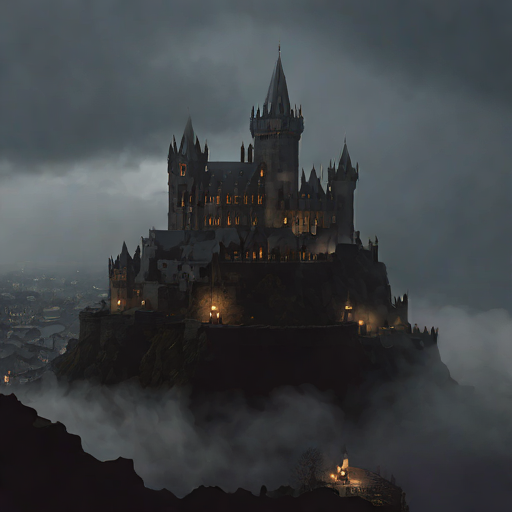

In [ ]:
display(image)

## Loading the Stable Diffusion XL Base Model

In [ ]:
from IPython.display import display
from diffusers import DiffusionPipeline
import torch

In [ ]:
pipeline = DiffusionPipeline.from_pretrained(
    "stabilityai/stable-diffusion-xl-base-1.0",
    torch_dtype = torch.float16,
    use_safetensors = True,
    variant = "fp16"
).to("cuda")

In [ ]:
prompt = "An ancient Gothic castle overlooking a misty medieval city, inspired by Edinburgh's Old Town, towering black stone walls, gothic arches, flying buttresses, glowing lanterns, dense fog, ravens, dramatic storm clouds, dark fantasy, highly detailed, cinematic, 8k"

In [ ]:
image = pipeline(
    prompt,
    num_inference_steps = 30
).images[0]

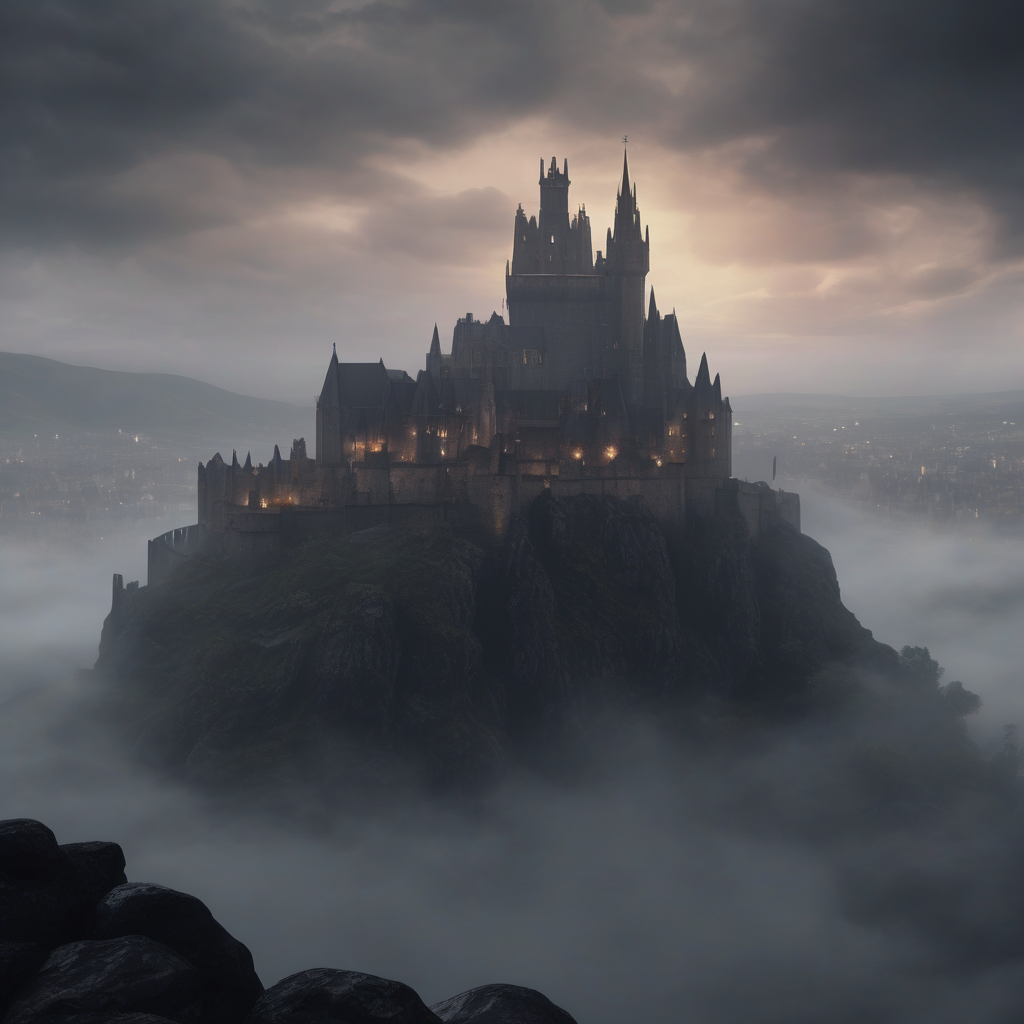

In [ ]:
display(image)

## Loading the Stable Diffusion XL Base Model with Refiner Model

In [ ]:
from IPython.display import display
from diffusers import DiffusionPipeline
import torch

In [ ]:
base = DiffusionPipeline.from_pretrained(
    "stabilityai/stable-diffusion-xl-base-1.0",
    torch_dtype = torch.float16,
    use_safetensors = True,
    variant = "fp16"
).to("cuda")

In [ ]:
refiner = DiffusionPipeline.from_pretrained(
    "stabilityai/stable-diffusion-xl-refiner-1.0",
    text_encoder_2 = base.text_encoder_2,
    vae = base.vae,
    torch_dtype = torch.float16,
    use_safetensors = True,
    variant = "fp16"
).to("cuda")

In [ ]:
n_steps = 40
denoising_split  = 0.8

In [ ]:
prompt = "An ancient Gothic castle overlooking a misty medieval city, inspired by Edinburgh's Old Town, towering black stone walls, gothic arches, flying buttresses, glowing lanterns, dense fog, ravens, dramatic storm clouds, dark fantasy, highly detailed, cinematic, 8k"

In [ ]:
image = base(
    prompt,
    num_inference_steps = n_steps,
    denoising_end = denoising_split,
    output_type = "latent"
).images[0]

In [ ]:
image = refiner(
    prompt,
    num_inference_steps = n_steps,
    denoising_start = denoising_split,
    image = image
).images[0]

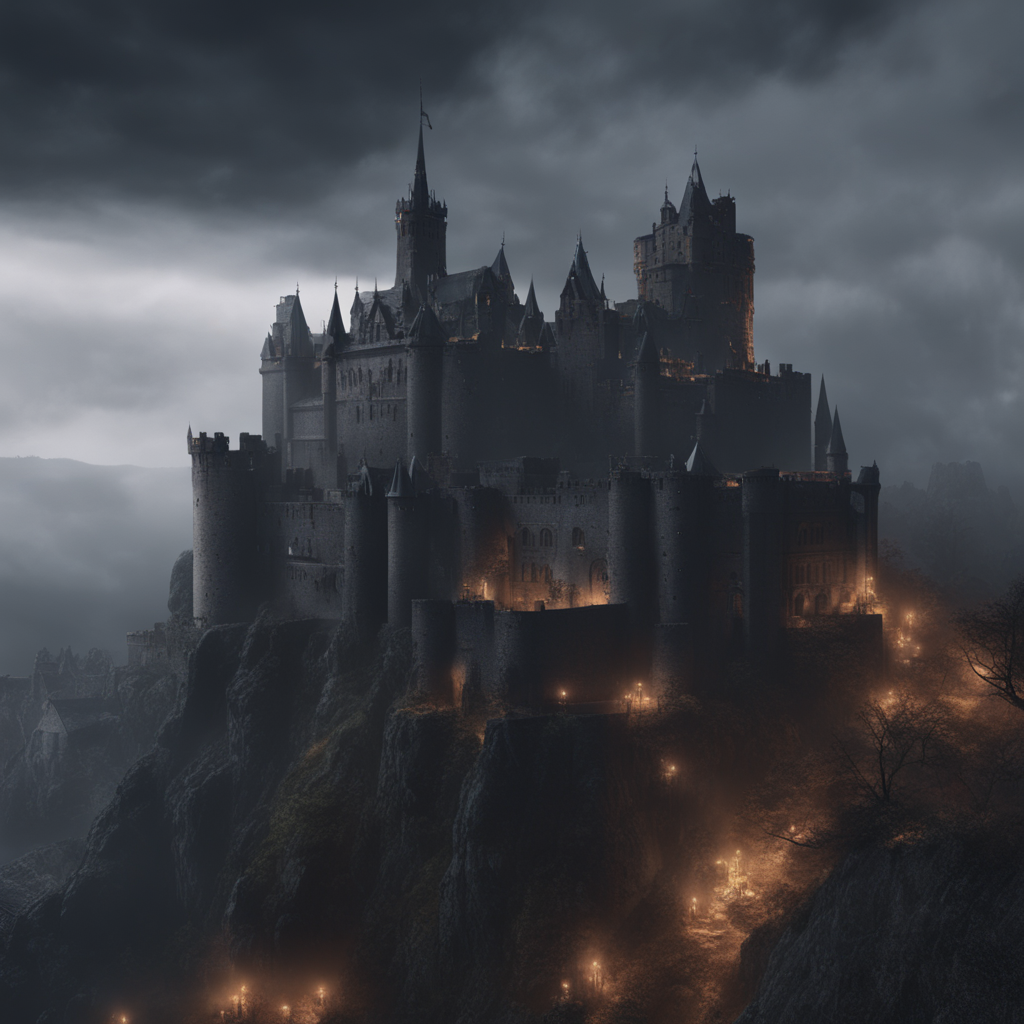

In [ ]:
display(image)

##